# 04 – Model Comparison
Compares the tuned Logistic Regression (notebook 02, MS26926476) and the tuned Random Forest (notebook 03, MS26936130). Both models were trained and evaluated on the same train/test split from notebook 01, using the same metrics.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import RocCurveDisplay

RANDOM_STATE = 42

## Comparison table

In [2]:
# results saved by notebooks 02 and 03
lr_results = pd.read_csv("../outputs/lr_results.csv", index_col=0)
rf_results = pd.read_csv("../outputs/rf_results.csv", index_col=0)

# compare the two tuned models (default threshold 0.5)
comparison = pd.concat([lr_results.loc[["LR tuned"]], rf_results.loc[["RF tuned"]]])
comparison.index = ["Logistic Regression", "Random Forest"]
comparison.round(3)

,Train accuracy,Test accuracy,Precision,Recall,F1-score,ROC-AUC
Logistic Regression,0.736,0.734,0.511,0.738,0.604,0.815
Random Forest,0.863,0.804,0.618,0.747,0.676,0.873


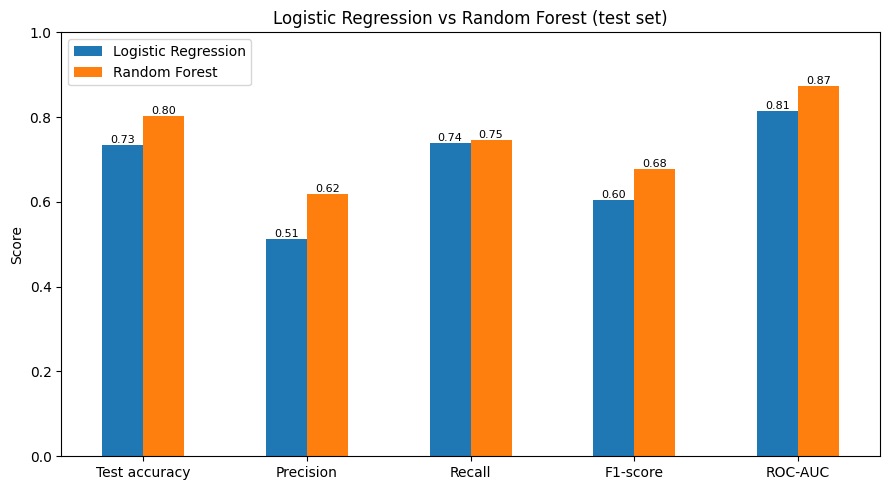

In [3]:
# test-set metrics side by side
metrics = ["Test accuracy", "Precision", "Recall", "F1-score", "ROC-AUC"]
ax = comparison[metrics].T.plot(kind="bar", figsize=(9, 5), rot=0)
ax.set_ylim(0, 1)
ax.set_ylabel("Score")
ax.set_title("Logistic Regression vs Random Forest (test set)")
for container in ax.containers:          # write the value on top of each bar
    ax.bar_label(container, fmt="%.2f", fontsize=8)
plt.tight_layout()
plt.savefig("../figures/comparison_metrics.png", dpi=300, bbox_inches="tight")
plt.show()

## ROC curves
To draw both ROC curves in one figure, the two tuned models are retrained with the best hyperparameters found in notebooks 02 and 03 (no new tuning). They reproduce the same test results.

In [4]:
train = pd.read_csv("../outputs/train.csv")
test = pd.read_csv("../outputs/test.csv")

X_train = train.drop(columns=["is_canceled"])
y_train = train["is_canceled"]
X_test = test.drop(columns=["is_canceled"])
y_test = test["is_canceled"]

In [5]:
# best Random Forest from notebook 03
cat_cols = X_train.select_dtypes(include="object").columns.tolist()
num_cols = X_train.select_dtypes(include="number").columns.tolist()

rf_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_cols),
        ("num", "passthrough", num_cols),
    ])),
    ("model", RandomForestClassifier(n_estimators=100, min_samples_leaf=5, max_features="sqrt",
                                     max_depth=None, class_weight="balanced",
                                     random_state=RANDOM_STATE, n_jobs=-1)),
])
rf_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](29,)","['hotel','lead_time','arrival_date_month',...,'total_guests', 'total_nights','has_previous_cancellation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,29
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

In [6]:
# best Logistic Regression from notebook 02 (same overlapping columns removed)
drop_cols = ["stays_in_weekend_nights", "stays_in_week_nights", "adults", "children", "babies",
             "arrival_date_week_number"]
X_train_lr = X_train.drop(columns=drop_cols)
X_test_lr = X_test.drop(columns=drop_cols)

cat_lr = X_train_lr.select_dtypes(include="object").columns.tolist()
num_lr = X_train_lr.select_dtypes(include="number").columns.tolist()

lr_model = Pipeline([
    ("preprocess", ColumnTransformer([
        ("cat", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=50), cat_lr),
        ("num", StandardScaler(), num_lr),
    ])),
    ("model", LogisticRegression(solver="liblinear", max_iter=2000, C=0.1,
                                 class_weight="balanced", random_state=RANDOM_STATE)),
])
lr_model.fit(X_train_lr, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocess', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](23,)","['hotel','lead_time','arrival_date_month',...,'total_guests', 'total_nights','has_previous_cancellation']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,23
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('cat', ...), ('num', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying `

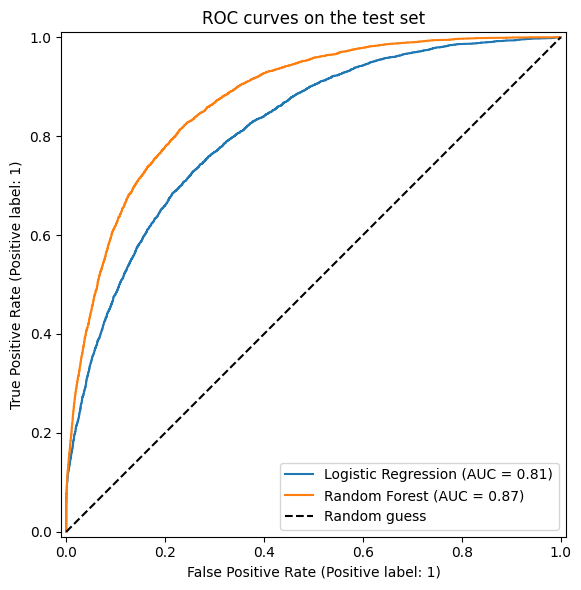

In [7]:
fig, ax = plt.subplots(figsize=(6, 6))
RocCurveDisplay.from_estimator(lr_model, X_test_lr, y_test, ax=ax, name="Logistic Regression")
RocCurveDisplay.from_estimator(rf_model, X_test, y_test, ax=ax, name="Random Forest")
ax.plot([0, 1], [0, 1], "k--", label="Random guess")
ax.set_title("ROC curves on the test set")
ax.legend()
plt.tight_layout()
plt.savefig("../figures/comparison_roc.png", dpi=300, bbox_inches="tight")
plt.show()

## Discussion
Random Forest performs better than Logistic Regression on every test metric: F1-score 0.676 vs 0.604, precision 0.618 vs 0.511, accuracy 0.804 vs 0.734 and ROC-AUC 0.873 vs 0.815. Recall is similar (0.747 vs 0.738), so both models find about three quarters of the cancellations, but Random Forest raises far fewer false alarms. Its ROC curve lies above the Logistic Regression curve at almost every threshold, so it ranks bookings by risk more accurately.

The main reason is that cancellation depends on features in non-linear ways and through interactions. For example, guests with one previous cancellation cancelled again 75% of the time, while guests with many previous cancellations almost never did. Random Forest can learn such patterns automatically, while Logistic Regression is limited to linear effects on the log-odds.

On the other hand, Logistic Regression does not overfit (train and test accuracy are almost equal), trains in about two seconds and is easier to interpret: its odds ratios show the direction and size of each effect, for example that every extra 30 days of lead time raises the odds of cancellation by about 23%. Random Forest only shows which features matter, not in which direction.

For a hotel that mainly wants accurate predictions, Random Forest is the better choice. Logistic Regression remains useful to explain the drivers of cancellation to managers.